## Introducción

Este cuaderno realiza un **barrido paramétrico** sobre el coeficiente de permeabilidad superficial $\kappa$ que aparece en la condición de contorno Robin en $z = d$:

$$D(z)\,\partial_z P - \kappa P = 0.$$

El parámetro $\kappa$ modela la adsorción/desorción en la superficie del sensor NV: $\kappa = 0$ corresponde a reflexión perfecta (superficie impermeable), mientras que $\kappa \to \infty$ equivale a absorción total. Se barren cinco valores: $\kappa \in \{0,\, 0.1,\, 1,\, 10,\, 100\}\,\text{nm/s}$.

Para cada $\kappa$ se recomputan las raíces radiales $\alpha_n$ (que dependen de $\kappa$ vía la ecuación de Robin), los modos axiales y la función $G(t)$. Parámetros fijos: $d = 15\,\text{nm}$, $R = L = 50d$, $D_0 = 2\times10^3\,\text{nm}^2/\mu\text{s}$, $D_s = 2\times10^1\,\text{nm}^2/\mu\text{s}$.

In [1]:
import os
import numpy as np
from scipy.special import jv
from scipy.sparse.linalg import eigsh, ArpackNoConvergence
from scipy.linalg import eigh_tridiagonal
from scipy.sparse import diags
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq
from joblib import Parallel, delayed
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# -----------------------------------------------------------------------------
# 0. Crear carpeta para archivos temporales (si no existe)
# -----------------------------------------------------------------------------
if not os.path.isdir("data/temp_G"):
    os.makedirs("data/temp_G")

In [3]:
# -----------------------------------------------------------------------------
# 1. Parámetros físicos (en nm y unidades compatibles)
# -----------------------------------------------------------------------------
# Conversión: 1 m = 1e9 nm.
d = 15 # Profundidad del NV en nm
D0 = 2e3 # 2e-9 * 1e18 # 2e-9 m²/us -> 2e9 nm²/s
D_s = 2e1 # nm^2/us
R = L = 50*d # 1e-6 m -> 1500 nm
delta = 2*d/3 # 1 nm (ancho de transición)
lambda_param = 0.75/d # en nm¹
n_modes_radial = 100 # Cantidad de modos de R()
m_max = 100 # Cantidad de modos de Z(z)
N_r = N_z = 45000 # Número de nodos en r y z
alpha_grid = 5.0 # Aglomeramiento de nodos cerca de z=0
z_c = lambda_param*L # altura crítica
# (Observación: 'varkappa' se fijará dentro del bucle

In [4]:
# -----------------------------------------------------------------------------
# 2. Malla adaptativa en z y perfil D(z) (NO depende de varkappa)
# -----------------------------------------------------------------------------
# 2.1 Construcción de la malla en z
j_vals = np.arange(N_z)
z = d + L * np.sinh(alpha_grid * j_vals / (N_z - 1)) / np.sinh(alpha_grid)
h = np.diff(z)  # h_j = z[j] - z[j-1]

# 2.2 Definición de D(z) (función)
def D(z_val):
    """
    Perfil de difusión completo con z en nm:
    D(z) = D_s + (D0 - D_s) * [ (1 - exp(-lambda_param*(z - d))) * (1 - S(z)) + S(z) ],
    con S(z) = 0.5 * [1 + tanh( (z - (z_c + d)) / delta ) ].
    """
    S = 0.5 * (1 + np.tanh((z_val - (z_c + d)) / delta))
    return D_s + (D0 - D_s) * ((1 - np.exp(-lambda_param * (z_val - d))) * (1 - S) + S)

In [5]:
# 2.3 Cálculo de D_values sobre toda la malla z
D_values = D(z)

# 2.4 Cálculo de D_eff (promedio armónico), que también se usa en tau = t * D_eff / d^2
integral_D = np.trapezoid(1.0 / D_values, z)
D_eff = L / integral_D

In [6]:
# -----------------------------------------------------------------------------
# 3. Definición de funciones compartidas:
#    - robin_eq(alpha): ecuación trascendental radial con parámetro varkappa
#    - R_func(alpha_array, rho_array): calcula los modos radiales J0(alpha_n * rho) normalizados
#    - build_system(n): ensambla y diagonaliza la parte axial para un modo radial n
# -----------------------------------------------------------------------------
def robin_eq(alpha, varkappa, D_eff):
    """
    Ecuación trascendental radial para hallar raíces alpha_n:
       alpha * J1(alpha*R) - (varkappa / D_eff) * J0(alpha*R) = 0.
    """
    return alpha * jv(1, alpha * R) - (varkappa / D_eff) * jv(0, alpha * R)

def find_alpha_roots(varkappa, D_eff, n_roots=n_modes_radial, step=1e-4):
    """
    Encuentra las primeras `n_roots` raíces alpha_n de robin_eq(alpha)=0
    en intervalos [0, ...] usando brentq y un paso `step`.
    """
    alpha_roots = []
    alpha_current = 0.0
    while len(alpha_roots) < n_roots:
        try:
            root = brentq(lambda a: robin_eq(a, varkappa, D_eff),
                          alpha_current, alpha_current + step, xtol=1e-6)
            alpha_roots.append(root)
            alpha_current = root + step
        except ValueError:
            alpha_current += step
    return np.array(alpha_roots)

def R_func(alpha_arr, rho_arr):
    """
    Calcula los modos radiales normalizados R_n(rho) = J0(alpha_n * rho)/sqrt(norm_n).
    Retorna:
      - R_normed: array con forma (n_modes_radial, len(rho_arr))
      - norms: vector con las normas (no se usa más adelante, pero lo dejamos para consistencia)
    """
    # alpha_arr: (n_modes_radial,)
    # rho_arr: (N_rhos,)
    alpha = alpha_arr.reshape(-1, 1)   # forma (n_modes_radial, 1)
    rho = rho_arr.reshape(1, -1)       # forma (1, N_rhos)
    R_matrix = jv(0, alpha * rho)      # (n_modes_radial, N_rhos)

    # Cálculo de normas analíticas: norms[n] = sqrt{ \int_0^R rho J0^2(alpha_n rho) d rho }
    J0R = jv(0, alpha_arr * R)  # (n_modes_radial,)
    J1R = jv(1, alpha_arr * R)  # (n_modes_radial,)
    norms = 0.5 * R ** 2 * (J0R**2 + J1R**2)  # (n_modes_radial,)
    norms = np.atleast_1d(norms)
    Nnorm = 1.0 / np.sqrt(norms)  # factor de normalización

    R_normed = Nnorm[:, None] * R_matrix  # (n_modes_radial, N_rhos)
    return R_normed, np.sqrt(norms)

def build_system(n, alpha_n, D_values, z, h, varkappa):
    """
    Ensambla y diagonaliza la parte axial para el modo radial n.

    Discretizacion en VOLUMEN FINITO sobre la malla no uniforme: integrando
    -d/dz(D dZ/dz) + alpha^2 D Z = Lambda Z sobre la celda [z_{j-1/2}, z_{j+1/2}]
    de ancho w_j se obtiene el problema generalizado SIMETRICO K Z = Lambda M Z,
    con M = diag(w_j) y

        K[j,j+1] = K[j+1,j] = -D_{j+1/2} / h_j
        K[j,j]   = D_{j-1/2}/h_{j-1} + D_{j+1/2}/h_j + alpha^2 D_j w_j

    Las celdas de los extremos son MEDIAS celdas (w_0 = h_0/2, w_{N-1} = h_{N-2}/2);
    en z = d va la condicion de Robin (+ varkappa) y en z = d+L la de Neumann.
    El sistema se simetriza con A = M^(-1/2) K M^(-1/2) y se diagonaliza con
    eigh_tridiagonal.

    Sustituye al ensamblado anterior, que (a) escribia lower_diag[-2] en vez de
    lower_diag[-1], dejando el ultimo nodo desacoplado y rompiendo la conservacion
    de masa, (b) dividia las filas de frontera por h_0 en vez de h_0/2, y
    (c) aplicaba varkappa tambien en z = d+L. Ademas evita ARPACK en modo
    shift-invert con sigma=0 sobre una matriz singular, que no convergia.

    Retorna: (n, (evals, evecs)) con evals los m_max autovalores mas bajos y
    evecs (N_z, m_max) normalizados con int Z^2 dz = 1.
    """
    alpha = alpha_n[n]
    N = len(z)

    # Anchos de celda (= pesos de la regla del trapecio)
    w_cell = np.empty(N)
    w_cell[1:-1] = 0.5 * (h[:-1] + h[1:])
    w_cell[0]    = 0.5 * h[0]
    w_cell[-1]   = 0.5 * h[-1]

    # Media armonica de D en las interfases j+1/2
    D_half = 2.0 * D_values[:-1] * D_values[1:] / (D_values[:-1] + D_values[1:])

    K_dia = np.zeros(N)
    K_dia[1:-1] = D_half[:-1] / h[:-1] + D_half[1:] / h[1:]
    K_dia[0]    = D_half[0] / h[0] + varkappa         # Robin en z = d
    K_dia[-1]   = D_half[-1] / h[-1]            # Neumann en z = d + L
    K_dia += alpha**2 * D_values * w_cell
    K_off = -D_half / h

    s = 1.0 / np.sqrt(w_cell)
    evals, V = eigh_tridiagonal(K_dia * s * s, K_off * s[:-1] * s[1:],
                                select='i', select_range=(0, m_max - 1))

    evecs = V * s[:, None]
    evecs /= np.sqrt(np.einsum('j,jm,jm->m', w_cell, evecs, evecs))[None, :]

    return (n, (np.maximum(evals, 0.0), evecs))

def T(t, lam):
    return np.exp(-np.abs(lam) * t)

def compute_P_vec(t, eigenvalues_ax, Z_tens, R0_mat, A_nm):
    """
    Computa P(ρ,z,t) más rápido usando matrices precalculadas.

    Parámetros:
    - t: escalar de tiempo
    - Z_tens: shape (Nz, n_modes_radial, m_max)
    - R0_mat: shape (n_modes_radial, N_r)
    - A_nm: coeficientes modales (n_modes_radial, m_max)

    Devuelve:
    - P: shape (Nz, Nr)
    """
    T_decay = T(t, eigenvalues_ax)  # (n_modes, m_max)
    W = A_nm * T_decay               # (n_modes, m_max)
    B = np.sum(Z_tens * W[None, :, :], axis=2)  # (Nz, n_modes)
    S = np.dot(R0_mat.T, B.T)  # (Nr, Nz)
    return S.T # np.maximum(S.T, 0)

In [7]:
# -----------------------------------------------------------------------------
# 4. Valores de varkappa a barrer (en nm/s)
# -----------------------------------------------------------------------------
varkappa_list = [0, 0.1, 1, 10, 100]

In [8]:
# -----------------------------------------------------------------------------
# 5. Malla temporal y pre-cálculo de J0(alpha_n * rho) y demás datos independientes
# -----------------------------------------------------------------------------
# 5.1 Nodos de integración en rho y z para G(t):
# N_quad = 1000
# rho_nodes = np.linspace(0.0, R, N_quad)  # np.linspace(0,R,N_quad)
# z_nodes = np.linspace(d, L + d, N_quad)   # en [d, L+d]
# rho0 = 0.0
# z0 = d
# dr = rho_nodes[1] - rho_nodes[0]
# dz = z_nodes[1] - z_nodes[0]

# # 5.2 Construcción de la red J0(alpha_n * rho) se hará DENTRO del bucle,
# #     porque alpha_n depende de varkappa.

# # 5.3 Construcción de Z_tens (modos axiales ante nodos z_nodes) se hará DENTRO del bucle,
# #     ya que los autovectores axiales dependen de varkappa.

# # 5.4 Matriz f_mat (factor dipolar) es independiente de varkappa:
# R2 = rho_nodes**2
# Z2 = z_nodes**2             # z_nodes ya empieza en d (distancia al NV)
# f_mat = (3 * Z2[None, :] - R2[:, None]) / (R2[:, None] + Z2[None, :])**2.5  # forma (N_quad, N_quad)
# f0_mat = (3*z0**2-rho0**2)/(rho0**2+z0**2)**2.5
# rho_factor = (rho_nodes[:, None] * f0_mat * f_mat * dr * dz)

# # 5.5 Vector de tiempos t en los que se evaluará G(t)
# t_values = np.logspace(-3, 4, N_quad)   # forma (N_quad,)
# tau_values = t_values * D_eff / d**2      # si se quiere comparar en unidades adimensionales

In [9]:
# -----------------------------------------------------------------------------
# 5. Malla temporal y pre-cálculo de f(ρ,z) y medida ρ dρ dz (independientes de varkappa)
# -----------------------------------------------------------------------------
# 5.1 Nodos de integración en rho y z para G(t):
# Malla de cuadratura para las integrales modales F_nm.
#
# El integrando esta muy concentrado cerca de la superficie: f decae como z^-3
# y los modos axiales tienen capa limite ahi. Con malla uniforme y suma
# rectangular (dr*dz*sum) la suma modal (5/16pi) sum F_nm^2 llegaba a superar a
# la integral directa (5/16pi) int f^2 rho drho dz, algo imposible para una
# identidad de Parseval truncada. Se agrupan nodos en la superficie con la misma
# transformacion sinh de la malla axial y se usan pesos del trapecio.
N_quad = 2000
_s = np.arange(N_quad) / (N_quad - 1)
rho_nodes = np.linspace(0.0, R, N_quad)                          # [0, R]
z_nodes   = d + L * np.sinh(alpha_grid * _s) / np.sinh(alpha_grid)  # [d, L+d]

def pesos_trapecio(x):
    """Pesos de la regla del trapecio para una malla posiblemente no uniforme."""
    h = np.diff(x)
    w = np.empty_like(x)
    w[1:-1] = 0.5 * (h[:-1] + h[1:])
    w[0]    = 0.5 * h[0]
    w[-1]   = 0.5 * h[-1]
    return w


w_rho = pesos_trapecio(rho_nodes)
w_z   = pesos_trapecio(z_nodes)

# 5.2 Factor dipolar f(ρ,z) en la malla (N_quad, N_quad)
R2 = rho_nodes**2
Z2 = z_nodes**2             # z_nodes ya empieza en d (distancia al NV)
# Kernel dipolar: f = (3cos^2(theta) - 1)/r^3 con cos(theta)=z/r, r^2=rho^2+z^2,
# es decir f = (3z^2 - r^2)/r^5 = (2z^2 - rho^2)/(rho^2+z^2)^{5/2}.
# (Antes: 3z^2 - rho^2; la resta va contra r^2, no contra rho^2. El prefactor
#  5/(16 pi) es [ (1/4)sqrt(5/pi) ]^2, el coeficiente de Y_2^0 al cuadrado.)
f_mat = (2 * Z2[None, :] - R2[:, None]) / (R2[:, None] + Z2[None, :])**2.5  # shape (Nr, Nz)

# 5.3 Medida cilíndrica ρ dρ dz con pesos del trapecio en ambas direcciones
F = (rho_nodes * w_rho)[:, None] * f_mat * w_z[None, :]   # (Nr, Nz)

# 5.5 Vector de tiempos t en los que se evaluará G(t)
t_values  = np.logspace(-3, 4, N_quad)    # (N_quad,)
tau_values = t_values * D_eff / d**2      # si se quiere comparar en unidades adimensionales

In [10]:
# -----------------------------------------------------------------------------
# 6. Bucle principal: para cada varkappa, calcular G(t) y guardarlo en un archivo temporal
# -----------------------------------------------------------------------------
for kapp in varkappa_list:
    print(f"--- Calculando G(t) para varkappa = {kapp} nm/s ---")

    # 6.1. Hallar raíces alpha_n (n_modes_radial valores)
    alpha_n = find_alpha_roots(kapp, D_eff, n_roots=n_modes_radial, step=1e-4)

    # 6.2. Modos radiales normalizados en nodos rho_nodes
    R0_mat, _ = R_func(alpha_n, rho_nodes)  # shape (n_modes_radial, N_quad)

    # 6.3. Resolver la parte axial en paralelo para cada modo radial n
    print("Resolviendo modos axiales...")
    axial_results = Parallel(n_jobs=4, verbose=1)(
        delayed(build_system)(n, alpha_n, D_values, z, h, kapp)
        for n in range(n_modes_radial)
    )

    # Recolectar autovalores y autovectores
    eigenvalues_ax = {}
    eigenvectors_ax = {}
    for n, (evals, evecs) in sorted(axial_results, key=lambda x: x[0]):
        eigenvalues_ax[n] = evals
        eigenvectors_ax[n] = evecs
    del axial_results
    
    # Apilado modo a modo, liberando el diccionario sobre la marcha: con una
    # comprension conviven la lista y el resultado (~7 GB para 100x100x45000).
    _evals = np.empty((n_modes_radial, m_max))
    _evecs = np.empty((n_modes_radial, m_max, len(z)))
    for n in range(n_modes_radial):
        _evals[n, :] = eigenvalues_ax[n]
        _evecs[n, :, :] = eigenvectors_ax.pop(n).T
    eigenvalues_ax = _evals
    eigenvectors_ax = _evecs
    del _evals, _evecs

    # 6.4. Normalizar cada modo axial en z (∫ Z^2 dz = 1)
    print("Normalizando...")
    norms_ax = np.sqrt(np.trapezoid(eigenvectors_ax**2, z, axis=2))  # (n_modes_radial, m_max)
    norms_ax[norms_ax == 0] = 1.0
    eigenvectors_ax /= norms_ax[:, :, None]
    del norms_ax
    # 6.5. Construir interpoladores cúbicos para Z_{n,m}(z) en z_nodes
    print("Interpolando...")
    # Se construye un spline VECTORIAL por modo radial (sus m_max modos a la vez)
    # y se evalua de inmediato; guardar los n_modes_radial * m_max = 10 000
    # splines escalares ocuparia ~14 GB (4 x N_z coeficientes cada uno).

    # 6.6. Proyeccion dipolar C_nm = int f(rho,z) R_n(rho) Z_nm(z) rho drho dz
    #      (antes aqui se proyectaba una condicion inicial tipo delta; la formula
    #       modal de G(t) no depende de la condicion inicial)
    print("Construyendo tensor de Z...")
    Z_tens = np.empty((N_quad, n_modes_radial, m_max))
    for n in range(n_modes_radial):
        cs_n = CubicSpline(z, eigenvectors_ax[n].T, axis=0, extrapolate=False)
        Z_tens[:, n, :] = cs_n(z_nodes)

    print("Proyectando el factor dipolar...")
    C_nm = np.zeros((n_modes_radial, m_max))
    for n in range(n_modes_radial):
        g_n = np.dot(R0_mat[n, :], F)          # (N_quad,) contraccion en rho
        for m in range(m_max):
            C_nm[n, m] = np.dot(g_n, Z_tens[:, n, m])
    B_rms_sq = (5.0 / (16.0 * np.pi)) * np.sum(C_nm**2)
    print(f"  B_rms^2 = {B_rms_sq:.4e}  ->  B_rms = {np.sqrt(abs(B_rms_sq)):.4e}")

    print("Calculando la autocorrelación...")
    G_values = np.zeros_like(t_values)
    for i, t_val in enumerate(t_values):
        T_decay = T(t_val, eigenvalues_ax)          # misma T(t, λ) definida antes
        G_values[i] = (5.0 / (16.0 * np.pi)) * np.sum((C_nm**2) * T_decay)

    # -----------------------------------------------------------------------------
    # 6.10. Guardar G_values en un archivo temporal y liberar memoria
    # -----------------------------------------------------------------------------
    print("Almacenando datos...")
    temp_filename = os.path.join("data/temp_G", f"G_kappa_{kapp}.dat")
    data_to_save  = np.column_stack([t_values, G_values])  # (N_quad, 2)
    header_str    = "Tiempo(s)   G_k{}".format(kapp)

    np.savetxt(
        temp_filename,
        data_to_save,
        header=header_str,
        fmt="%.9e",
        comments=''
    )

    # Liberamos G_values inmediatamente
    del G_values
    del data_to_save
    del Z_tens

    print(f"  → Guardado temporal en '{temp_filename}' y liberado G_values.\n")

--- Calculando G(t) para varkappa = 0 nm/s ---
Resolviendo modos axiales...


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   37.7s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  1.3min finished


Normalizando...
Interpolando...
Construyendo tensor de Z...
Proyectando el factor dipolar...
  B_rms^2 = 3.6805e-06  ->  B_rms = 1.9185e-03
Calculando la autocorrelación...
Almacenando datos...
  → Guardado temporal en 'data/temp_G\G_kappa_0.dat' y liberado G_values.

--- Calculando G(t) para varkappa = 0.1 nm/s ---
Resolviendo modos axiales...


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   33.7s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  1.3min finished


Normalizando...
Interpolando...
Construyendo tensor de Z...
Proyectando el factor dipolar...
  B_rms^2 = 3.6805e-06  ->  B_rms = 1.9184e-03
Calculando la autocorrelación...
Almacenando datos...
  → Guardado temporal en 'data/temp_G\G_kappa_0.1.dat' y liberado G_values.

--- Calculando G(t) para varkappa = 1 nm/s ---
Resolviendo modos axiales...


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   35.1s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  1.3min finished


Normalizando...
Interpolando...
Construyendo tensor de Z...
Proyectando el factor dipolar...
  B_rms^2 = 3.6804e-06  ->  B_rms = 1.9184e-03
Calculando la autocorrelación...
Almacenando datos...
  → Guardado temporal en 'data/temp_G\G_kappa_1.dat' y liberado G_values.

--- Calculando G(t) para varkappa = 10 nm/s ---
Resolviendo modos axiales...


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   33.6s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  1.2min finished


Normalizando...
Interpolando...
Construyendo tensor de Z...
Proyectando el factor dipolar...
  B_rms^2 = 3.6797e-06  ->  B_rms = 1.9183e-03
Calculando la autocorrelación...
Almacenando datos...
  → Guardado temporal en 'data/temp_G\G_kappa_10.dat' y liberado G_values.

--- Calculando G(t) para varkappa = 100 nm/s ---
Resolviendo modos axiales...


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   32.4s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  1.2min finished


Normalizando...
Interpolando...
Construyendo tensor de Z...
Proyectando el factor dipolar...
  B_rms^2 = 3.6546e-06  ->  B_rms = 1.9117e-03
Calculando la autocorrelación...
Almacenando datos...
  → Guardado temporal en 'data/temp_G\G_kappa_100.dat' y liberado G_values.



In [11]:
# --------------------------------------------------------
# 7. Al terminar el bucle, combinamos todos los archivos temporales
# --------------------------------------------------------
print("→ Combinando archivos temporales en 'VariateKappa_G_vs_t.dat' ...")

primero = True
lista_Gcols = []

for kapp in varkappa_list:
    temp_filename = os.path.join("data/temp_G", f"G_kappa_{kapp}.dat")
    # Ahora le decimos a loadtxt que omita la cabecera (1 línea)
    arr = np.loadtxt(temp_filename, skiprows=1)   # forma (N_quad, 2)

    if primero:
        t_col = arr[:, 0]   # extraemos el vector de tiempos
        primero = False
    G_col = arr[:, 1]       # extraemos la columna G(t) para este kappa
    lista_Gcols.append(G_col)

# Después seguimos exactamente igual:
G_stack = np.vstack(lista_Gcols).T               # (N_quad, 8)
output_data = np.column_stack([t_col, G_stack])  # (N_quad, 1 + 8)

header_cols = ['Tiempo(s)'] + [f'G_k{int(kp*10)}' for kp in varkappa_list]
header_str = '   '.join(header_cols)

np.savetxt(
    "data/VariateKappa_G_vs_t.dat",
    output_data,
    header=header_str,
    fmt="%.9e",
    comments=''
)

print("→ Archivo final 'VariateKappa_G_vs_t.dat' creado con columnas:")
print("   ", header_cols)

→ Combinando archivos temporales en 'VariateKappa_G_vs_t.dat' ...
→ Archivo final 'VariateKappa_G_vs_t.dat' creado con columnas:
    ['Tiempo(s)', 'G_k0', 'G_k1', 'G_k10', 'G_k100', 'G_k1000']


In [12]:
df = pd.read_csv("data/VariateKappa_G_vs_t.dat",sep=r'\s+',comment='#')

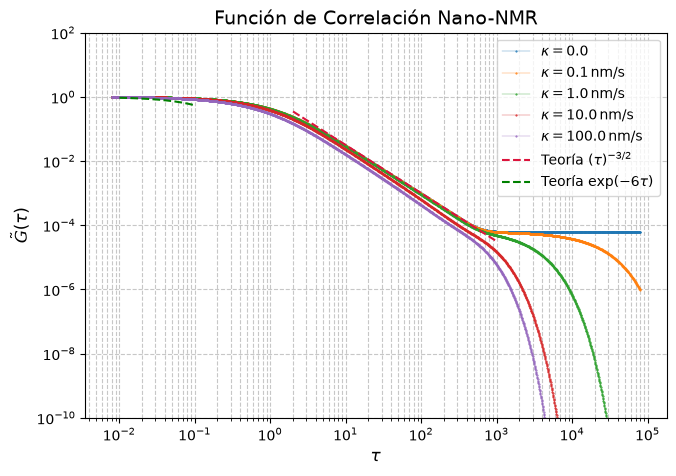

In [13]:
plt.figure(figsize=(7.5,5))
plt.loglog(tau_values, df.G_k0/df.G_k0[0], "o-", label=r"$\kappa=0.0$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_k1/df.G_k1[0], "o-", label=r"$\kappa=0.1\,\text{nm/s}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_k10/df.G_k10[0], "o-", label=r"$\kappa=1.0\,\text{nm/s}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_k100/df.G_k100[0], "o-", label=r"$\kappa=10.0\,\text{nm/s}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values, df.G_k1000/df.G_k1000[0], "o-", label=r"$\kappa=100.0\,\text{nm/s}$", markersize=0.5, linewidth=0.25)
plt.plot(tau_values[(tau_values>=2)&(tau_values<=1000)], tau_values[(tau_values>=2)&(tau_values<=1000)]**-1.5, "--", label=r"Teoría $(\tau)^{-3/2}$", color="crimson", linewidth=1.5)
plt.plot(tau_values[(tau_values>=1e-2)&(tau_values<=0.1)], np.exp(-6*tau_values[(tau_values>=1e-2)&(tau_values<=0.1)]), "--", label=r"Teoría $\exp(-6\tau)$", color="green", linewidth=1.5)
# plt.xlabel("Tiempo (s)", fontsize=12)
plt.xlabel(r"$\tau$", fontsize=12)
plt.ylabel(r"$\tilde{G}(\tau)$", fontsize=12)
plt.title("Función de Correlación Nano-NMR", fontsize=14)
plt.legend()
plt.ylim((1e-10,1e2))
plt.grid(which="both", ls='--', alpha=0.7)
plt.savefig("figuras/correlacion_nanoNMR_kappaVariation.pdf", bbox_inches="tight", dpi=300)
plt.show()
plt.close()

## Conclusiones

El barrido sobre $\kappa$ revela la influencia de la condición de frontera en la dinámica de correlación:

- Para $\kappa = 0$ (superficie totalmente reflectante), $G(t)$ es máxima a tiempos largos y exhibe el decaimiento más lento, pues las moléculas permanecen en el volumen.
- Al aumentar $\kappa$, la superficie absorbe moléculas con mayor eficiencia, acelerando el decaimiento de $G(t)$ a tiempos intermedios y modificando la amplitud relativa de los modos axiales con $n > 0$.
- Los regímenes asintóticos $\exp(-6\tau)$ (tiempos cortos) y $\tau^{-3/2}$ (tiempos largos) son robustos frente a variaciones de $\kappa$, aunque la amplitud de la transición y la posición del cruce entre regímenes sí dependen de este parámetro.

Este análisis sirve para calibrar el modelo contra mediciones experimentales donde la superficie puede tener distinto grado de funcionalización química.